In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [11]:
def load_and_preprocess(img_path, target_size=(224, 224)):

    img = Image.open(img_path)

    if img.mode != 'RGB':
        img = img.convert('RGB')

    img = img.resize(target_size)

    arr = np.array(img, dtype=np.float32) / 255.0 

    return arr

In [14]:
sample_path = "../data/train/cat/" + os.listdir("../data/train/cat")[0]

arr = load_and_preprocess(sample_path)

print(f"Shape  : {arr.shape}")        
print(f"Min    : {arr.min():.4f}")     
print(f"Max    : {arr.max():.4f}")    
print(f"Dtype  : {arr.dtype}")          

Shape  : (224, 224, 3)
Min    : 0.0000
Max    : 1.0000
Dtype  : float32


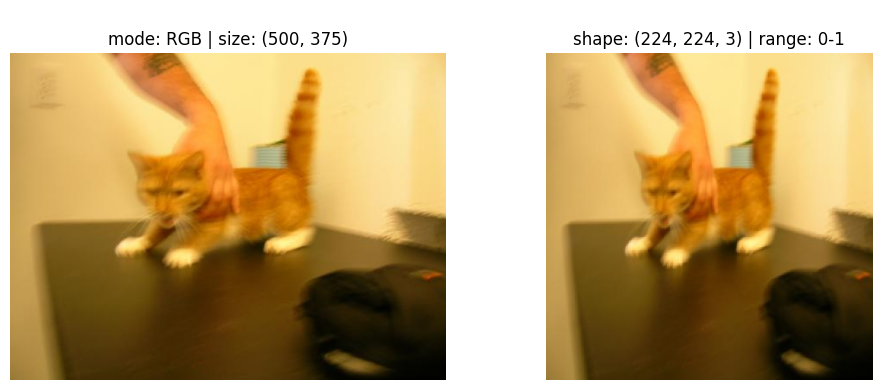

In [ ]:
# ลอง Preprocess ก่อน 1 รูป
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# ก่อน
raw = Image.open(sample_path)
axes[0].imshow(raw)
axes[0].set_title(f"\nmode: {raw.mode} | size: {raw.size}")
axes[0].axis('off')

# หลัง
axes[1].imshow(arr)
axes[1].set_title(f"\nshape: {arr.shape} | range: 0-1")
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [19]:
# Preprocess ทุกรูปเลย
errors = []
splits = ['train', 'val', 'test']
classes = ['cat', 'dog']

for split in splits:
    for cls in classes:
        folder = f"data/{split}/{cls}"
        if not os.path.exists(folder):
            continue
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            try:
                arr = load_and_preprocess(fpath)
                assert arr.shape == (224, 224, 3)
                assert arr.min() >= 0.0 and arr.max() <= 1.0
            except Exception as e:
                errors.append((fpath, str(e)))

if errors:
    print(f"errors {len(errors)} รูป:")
    for path, err in errors:
        print(f"   {path} → {err}")
else:
    print("Preprocessing is complete. ")

Preprocessing is complete. 
